In [ ]:
library(ggplot2)
library(dplyr)
library(grid)


root <- getwd()
if (basename(root) == "figure_code") root <- dirname(root)
repo_dir <- file.path(root, "data")

fig5_data <- readRDS(file.path(repo_dir, "fig5_plot_data.rds"))

slope_df    <- fig5_data$slope
gradient_df <- fig5_data$gradient
change_df   <- fig5_data$change

In [27]:
flevel_order <- c("lv", "mv", "hv", "sm")
flevel_labels <- c(lv = "low visual", mv = "mid visual", hv = "high visual", sm = "semantic")
flevel_labels_title <- c(lv = "Low visual", mv = "Mid visual", hv = "High visual", sm = "Semantic")

pal <- c(lv = "#1E5E4D", mv = "#2E8C8A", hv = "#7FBFA6", sm = "#E6D7B1")

slope_df <- slope_df %>%
  mutate(
    state = factor(state, levels = c("encoding", "recall"), labels = c("Encoding", "Recall")),
    flevel = factor(flevel, levels = flevel_order)
  )

gradient_df <- gradient_df %>%
  mutate(
    state = factor(state, levels = c("encoding", "recall")),
    flevel = factor(flevel, levels = flevel_order)
  )

change_df <- change_df %>%
  mutate(flevel = factor(flevel, levels = flevel_order))

base_theme <- theme_minimal(base_size = 16) +
  theme(
    legend.position = "top",
    legend.title = element_blank(),
    legend.text = element_text(size = 16),
    legend.key.width = unit(1.2, "cm"),
    strip.text = element_text(size = 20, face = "bold"),
    strip.background = element_rect(fill = "grey95", color = NA),
    axis.title = element_text(size = 20),
    axis.title.x = element_text(margin = margin(t = 8)),
    axis.title.y = element_text(margin = margin(r = 8)),
    axis.text = element_text(size = 13, color = "grey30"),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_line(linewidth = 0.3),
    panel.spacing = unit(1.2, "lines"),
    plot.margin = margin(15, 15, 15, 15)
  )

### Fig 1d

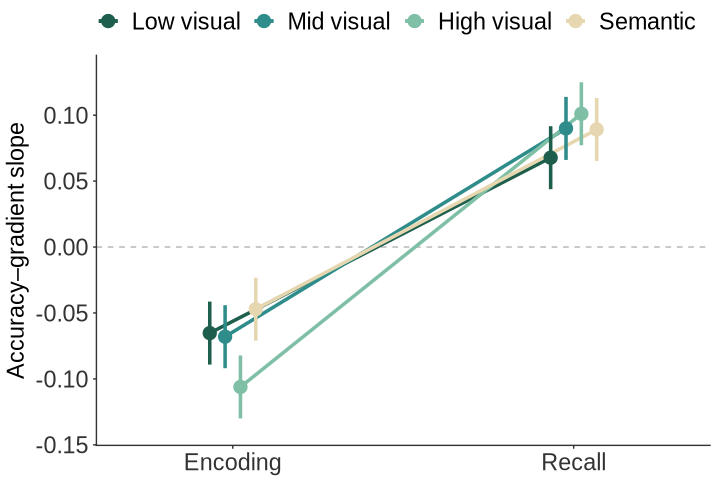

In [29]:
options(repr.plot.width = 6, repr.plot.height = 4)
pd <- position_dodge(width = 0.18)

p_gradient <- ggplot(
  slope_df,
  aes(x = state, y = estimate, group = flevel, color = flevel)
) +
  geom_hline(yintercept = 0, linewidth = 0.4, linetype = "dashed", color = "grey70") +
  geom_line(linewidth = 1, position = pd) +
  geom_errorbar(aes(ymin = lower, ymax = upper), width = 0, linewidth = 1, position = pd) +
  geom_point(aes(fill = flevel), shape = 21, size = 2.7, stroke = 1, position = pd) +
  scale_color_manual(values = pal, labels = flevel_labels_title, aesthetics = c("color", "fill")) +
  scale_x_discrete(expand = expansion(add = 0.4)) +
  scale_y_continuous(expand = expansion(mult = 0.08)) +
  labs(x = NULL, y = "Accuracy–gradient slope", color = NULL, fill = NULL) +
  theme_classic(base_size = 14) +
  theme(
    axis.line = element_line(linewidth = 0.4, color = "grey20"),
    axis.ticks = element_line(linewidth = 0.4, color = "grey20"),
    axis.ticks.length = unit(2, "pt"),
    axis.title.y = element_text(margin = margin(r = 4)),
    axis.text = element_text(size = 14, color = "grey20"),
    legend.position = "top",
    legend.justification = "left",
    legend.direction = "horizontal",
    legend.text = element_text(size = 14),
    legend.key.width = unit(0.5, "cm"),
    legend.margin = margin(b = -2),
    plot.margin = margin(4, 6, 3, 4)
  )

p_gradient

### Fig 5

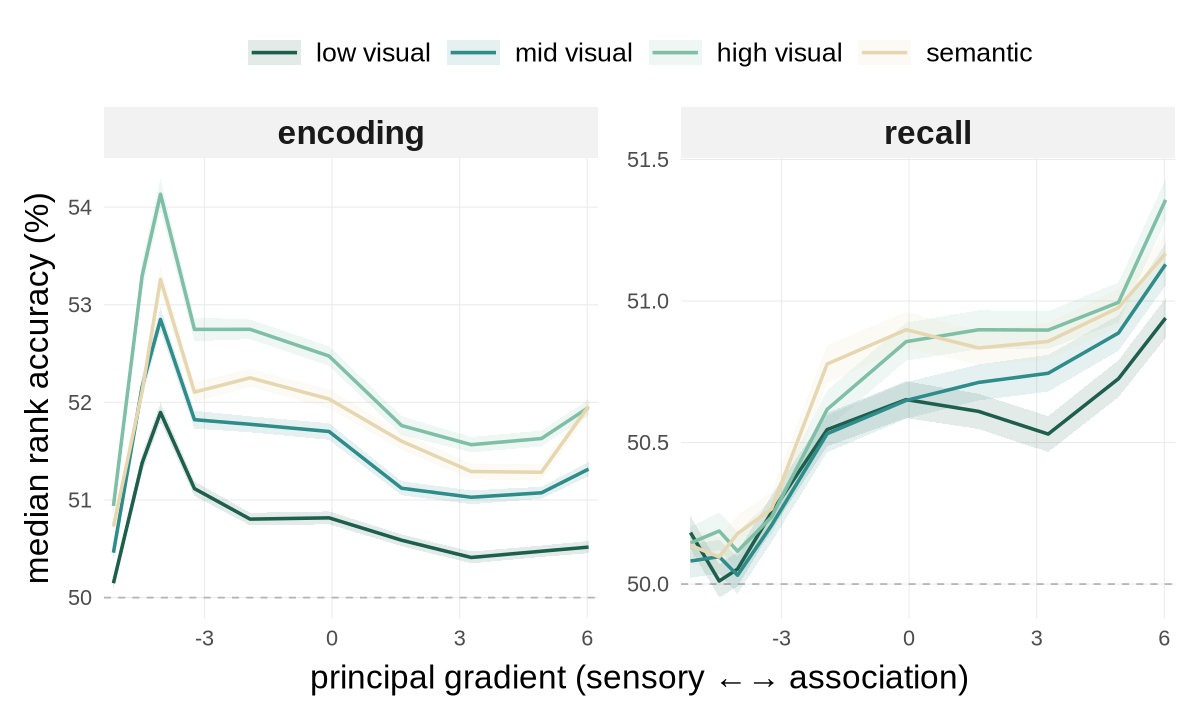

In [23]:
options(repr.plot.width = 10, repr.plot.height = 6)

p_raw <- ggplot(
  gradient_df,
  aes(x = g, y = acc, color = flevel, fill = flevel, group = flevel)
) +
  geom_hline(yintercept = 50, linetype = "dashed", color = "grey70", linewidth = 0.5) +
  geom_ribbon(aes(ymin = acc - se, ymax = acc + se), alpha = 0.12, color = NA) +
  geom_line(linewidth = 1) +
  facet_wrap(~state, scales = "free_y") +
  scale_color_manual(values = pal, labels = flevel_labels) +
  scale_fill_manual(values = pal, labels = flevel_labels) +
  scale_x_continuous(expand = expansion(mult = 0.02)) +
  labs(
    x = "principal gradient (sensory \u2190\u2192 association)",
    y = "median rank accuracy (%)",
    color = "feature",
    fill = "feature"
  ) +
  base_theme

p_raw

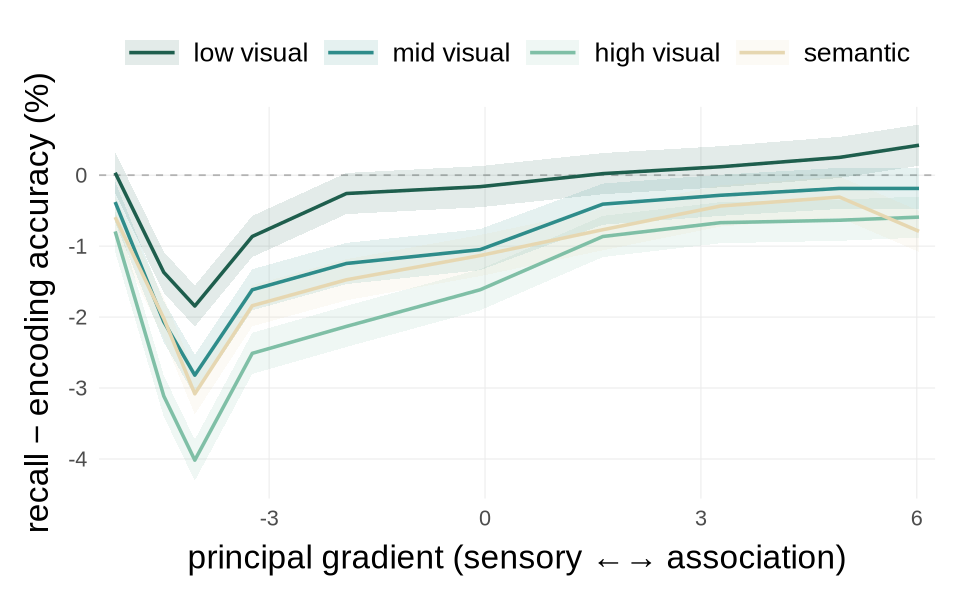

In [25]:
options(repr.plot.width = 8, repr.plot.height = 5)

p_chg <- ggplot(
  change_df,
  aes(x = g, y = change, color = flevel, fill = flevel, group = flevel)
) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "grey70", linewidth = 0.5) +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.12, color = NA) +
  geom_line(linewidth = 1) +
  scale_color_manual(values = pal, labels = flevel_labels) +
  scale_fill_manual(values = pal, labels = flevel_labels) +
  scale_x_continuous(expand = expansion(mult = 0.02)) +
  labs(
    x = "principal gradient (sensory \u2190\u2192 association)",
    y = "recall \u2212 encoding accuracy (%)"
  ) +
  base_theme

p_chg